Training baseline classical ML models

In [1]:
!pip install deepchem rdkit catboost xgboost

In [2]:
import deepchem as dc

No normalization for SPS. Feature removed!
No normalization for AvgIpc. Feature removed!
Skipped loading some Tensorflow models, missing a dependency. No module named 'tensorflow'
Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch_geometric'
Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (/opt/anaconda3/envs/cheminfo/lib/python3.11/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'jax'
Skipped loading some PyTorch models, missing a dependency. No module named 'tensorflow'


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt
import catboost
import xgboost

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


print(dc.__version__)
print(sns.__version__)
print(np.__version__)
print(sklearn.__version__)
print(scipy.__version__)
print(matplotlib.__version__)
print(xgboost.__version__)
print(catboost.__version__)

2.8.0
0.13.2
2.4.6
1.9.1
1.17.1
3.11.2
3.4.2
1.2.10


In [4]:
print(sorted(dc.molnet.featurizers))
print(sorted(dc.molnet.splitters))
print(sorted(dc.molnet.transformers))

['ecfp', 'graphconv', 'onehot', 'raw', 'smiles2img', 'weave']
['butina', 'fingerprint', 'index', 'random', 'scaffold', 'stratified', 'task']
['balancing', 'clipping', 'log', 'minmax', 'normalization']


In [5]:
tasks, datasets, transformers = dc.molnet.load_lipo(featurizer='ecfp',
                                                   splitter='scaffold',
                                                   transformers=['normalization'])
train_dataset, valid_dataset, test_dataset = datasets
train_dataset

<DiskDataset X.shape: (np.int64(3360), np.int64(1024)), y.shape: (np.int64(3360), np.int64(1)), w.shape: (np.int64(3360), np.int64(1)), task_names: ['exp']>

In [6]:
smiles = train_dataset.ids
smiles

array(['CC(C)NCC(O)COc1ccc(COCCOC(C)C)cc1', 'Cc1ccc(NC(=N)N)cc1C',
       'CC(C)C(=O)NCCNCC(O)COc1ccc(O)cc1', ...,
       'Cn1cnc(c1Sc2ncnc3nc[nH]c23)[N+](=O)[O-]',
       'OCCN1CCN(Cc2ccc3c(NC(=O)CC45CC6CC(CC(C6)C4)C5)c(Cl)ccc3n2)CC1',
       'OC(=O)c1cccnc1Nc2cccc(c2)C(F)(F)F'], shape=(3360,), dtype=object)

In [7]:
X_train, y_train = train_dataset.X, train_dataset.y[:, 0]
X_valid, y_valid = valid_dataset.X, valid_dataset.y[:, 0]
X_test, y_test = test_dataset.X, test_dataset.y[:, 0]

print(X_train.shape, X_valid.shape, X_test.shape)
print(y_train.min(), y_train.max(), y_train.std())

(3360, 1024) (420, 1024) (420, 1024)
-3.0247122289148565 1.9299001765826398 1.000000000000001


In [ ]:
models = {
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "RandomForest": RandomForestRegressor(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_jobs=-1, random_state=42),
    "CatBoost": CatBoostRegressor(random_state=42),
    "HistGBM": HistGradientBoostingRegressor(random_state=42)
}

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_rmse = {}
for name, model in models.items():
    scores = -cross_val_score(model, X_train, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error")
    cv_rmse[name] = scores.mean()

Streaming output truncated to the last 5000 lines.
4:	learn: 0.9775798	total: 110ms	remaining: 22s
5:	learn: 0.9726074	total: 122ms	remaining: 20.3s
6:	learn: 0.9677170	total: 137ms	remaining: 19.4s
7:	learn: 0.9625450	total: 150ms	remaining: 18.6s
8:	learn: 0.9590190	total: 163ms	remaining: 18s
9:	learn: 0.9550532	total: 180ms	remaining: 17.8s
10:	learn: 0.9518753	total: 199ms	remaining: 17.9s
11:	learn: 0.9490725	total: 214ms	remaining: 17.6s
12:	learn: 0.9445831	total: 229ms	remaining: 17.3s
13:	learn: 0.9399763	total: 247ms	remaining: 17.4s
14:	learn: 0.9344147	total: 260ms	remaining: 17.1s
15:	learn: 0.9295029	total: 273ms	remaining: 16.8s
16:	learn: 0.9257721	total: 289ms	remaining: 16.7s
17:	learn: 0.9226509	total: 309ms	remaining: 16.8s
18:	learn: 0.9191137	total: 326ms	remaining: 16.8s
19:	learn: 0.9161961	total: 338ms	remaining: 16.6s
20:	learn: 0.9143732	total: 350ms	remaining: 16.3s
21:	learn: 0.9110248	total: 361ms	remaining: 16.1s
22:	learn: 0.9082153	total: 373ms	remaini

In [ ]:
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    for split, X, y_true in [("valid", X_valid, y_valid), ("test", X_test, y_test)]:
        y_pred = model.predict(X)
        rows.append({
            "model": name,
            "split": split,
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred),
        })

results = pd.DataFrame(rows)
results

Learning rate set to 0.049584
0:	learn: 0.9925596	total: 14.5ms	remaining: 14.5s
1:	learn: 0.9864842	total: 29.4ms	remaining: 14.7s
2:	learn: 0.9807768	total: 43.9ms	remaining: 14.6s
3:	learn: 0.9758735	total: 58.2ms	remaining: 14.5s
4:	learn: 0.9700927	total: 73.9ms	remaining: 14.7s
5:	learn: 0.9655865	total: 87.7ms	remaining: 14.5s
6:	learn: 0.9597798	total: 102ms	remaining: 14.5s
7:	learn: 0.9551893	total: 116ms	remaining: 14.4s
8:	learn: 0.9514737	total: 130ms	remaining: 14.3s
9:	learn: 0.9461997	total: 144ms	remaining: 14.3s
10:	learn: 0.9422762	total: 158ms	remaining: 14.2s
11:	learn: 0.9391969	total: 173ms	remaining: 14.2s
12:	learn: 0.9354310	total: 186ms	remaining: 14.2s
13:	learn: 0.9325017	total: 203ms	remaining: 14.3s
14:	learn: 0.9297485	total: 218ms	remaining: 14.3s
15:	learn: 0.9266994	total: 233ms	remaining: 14.3s
16:	learn: 0.9235776	total: 247ms	remaining: 14.3s
17:	learn: 0.9203619	total: 262ms	remaining: 14.3s
18:	learn: 0.9175845	total: 276ms	remaining: 14.3s
19:	l

,model,split,RMSE,MAE,R2
0,SVR,valid,0.829133,0.660611,0.319745
1,SVR,test,0.763864,0.601201,0.297880
2,RandomForest,valid,0.827174,0.662212,0.322954
3,RandomForest,test,0.775868,0.624774,0.275638
4,XGBoost,valid,0.804559,0.633122,0.359469
5,XGBoost,test,0.766142,0.595334,0.293685
6,CatBoost,valid,0.777378,0.615335,0.402018
7,CatBoost,test,0.743769,0.594547,0.334336
8,HistGBM,valid,0.789686,0.621505,0.382933
9,HistGBM,test,0.738953,0.584730,0.342928


Metrics

In [ ]:
table = (
    results.pivot(index="model", columns="split", values=["RMSE", "MAE", "R2"]).round(3).sort_values(("RMSE", "test"))
)
table

RMSE           MAE            R2       
split          test  valid   test  valid   test  valid
model                                                 
HistGBM       0.739  0.790  0.585  0.622  0.343  0.383
CatBoost      0.744  0.777  0.595  0.615  0.334  0.402
SVR           0.764  0.829  0.601  0.661  0.298  0.320
XGBoost       0.766  0.805  0.595  0.633  0.294  0.359
RandomForest  0.776  0.827  0.625  0.662  0.276  0.323

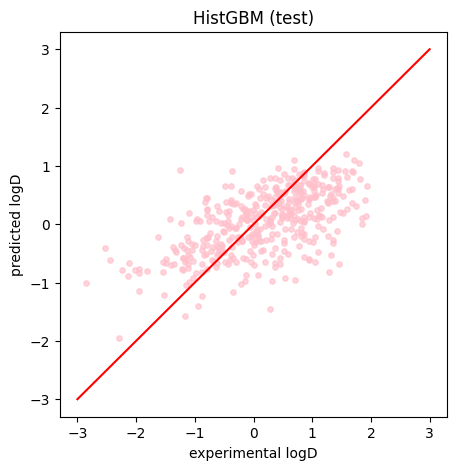

In [ ]:
best = table.index[0]
y_pred = models[best].predict(X_test)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, y_pred, alpha=0.67, s=15, color='pink')
ax.plot([-3, 3], [-3, 3], color="red")
ax.set_xlabel("experimental logD")
ax.set_ylabel("predicted logD")
ax.set_title(best + " (test)")
plt.show()

Well, it ain't much, but it's honest work. For the most promising models (boosting models) as the next step it makes sense to do hyperparameter tuning and try descriptors instead of circular fingerprints.

In [ ]:
#========================================================================================================================